# Workshop No. 2: Modelo Avanzado de Aprendizaje Profundo y Fine-Tuning con MovieLens 32M (5%)

## Objetivo y Alcance
En este notebook se desarrolla, entrena, monitorea y evalúa un modelo de aprendizaje profundo para el sistema de recomendación sobre el conjunto de datos **MovieLens 32M (`ml-32m`)**, configurado al **5% del dataset (`SAMPLE_FRACTION = 0.05`)** para ejecutar el flujo completo de preentrenamiento y **fine-tuning** en dos etapas conforme a los requerimientos de `Workshop_2.pdf`:

1. **Selección e Implementación de Arquitectura**: Red Híbrida de Filtrado Colaborativo Neuronal (**HybridNeuMF**) que combina una rama bilineal de Factorización Matricial Generalizada (GMF con sesgos de usuario y película) y una torre **Deep MLP** enriquecida con características de contenido (géneros multi-hot y año de estreno estandarizado), regularizada mediante **Batch Normalization**, **Layer Normalization**, **Dropout** y **Weight Decay**.
2. **Manejo de Problemas de Datos (Workshop 1)**: Partición estricta en **Entrenamiento (70%)**, **Validación (15%)** y **Prueba (15%)** antes de cualquier codificación para evitar fuga de datos (*data leakage*), uso de token `<UNK>` (`padding_idx = 0`) para usuarios/películas no vistos (*cold-start*), y ponderación inversa por frecuencia de calificaciones para compensar el desbalance hacia calificaciones altas.
3. **Estrategia de Transfer Learning y Fine-Tuning**:
   - **Preentrenamiento Base**: Obtención de representaciones latentes base mediante Factorización Matricial Supervisada (equivalente al modelo base de Workshop 1).
   - **Fase 1 (Warm-up de Cabeza Específica)**: Congelamiento de las capas de embeddings preentrenadas (`requires_grad = False`) y entrenamiento exclusivo de la torre Deep MLP y cabeza de fusión durante 6 épocas.
   - **Fase 2 (Fine-Tuning Extremo a Extremo)**: Descongelamiento de toda la arquitectura y ajuste fino conjunto durante 12 épocas con tasa de aprendizaje reducida y planificador **Cosine Annealing (`CosineAnnealingLR`)**.
4. **Monitoreo, Evaluación en Test y Checkpoint**: Registro de métricas por época en `runs/`, curvas de aprendizaje, comparación integral en el conjunto de prueba frente a los *baselines* de Workshop 1 (con intervalos de confianza por *bootstrapping* y análisis por segmentos), y almacenamiento/verificación del mejor modelo en `checkpoints/model_best.pt`.

## 1. Configuración del Entorno, Hiperparámetros y Semillas de Reproducibilidad

Se definen todas las constantes del experimento, fijando `SAMPLE_FRACTION = 0.05` (5% del dataset `ml-32m`), semillas aleatorias (`SEED = 42`), hiperparámetros de regularización, tasas de aprendizaje para cada fase de *fine-tuning* y rutas para el almacenamiento de checkpoints (`checkpoints/model_best.pt`) y logs de entrenamiento (`runs/`).

In [35]:
import json
import math
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import (
     confusion_matrix,
     f1_score,
     mean_absolute_error,
     precision_score,
     recall_score,
     roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
SAMPLE_FRACTION = 0.15
CHUNK_SIZE = 1_000_000

GMF_DIM = 16
MLP_EMB_DIM = 16
GENRE_PROJ_DIM = 16
MLP_HIDDEN_DIMS = (64, 32)
DROPOUT_RATE = 0.35

BATCH_SIZE = 4096
EVAL_BATCH_SIZE = 16384

PRETRAIN_EPOCHS = 4
PRETRAIN_LR = 2e-3
PRETRAIN_WD = 1e-3

PHASE1_EPOCHS = 5
PHASE1_LR = 1e-3
PHASE1_WD = 1e-4

PHASE2_EPOCHS = 20
PHASE2_LR = 1e-4
PHASE2_MIN_LR = 1e-5
PHASE2_WD = 1e-4
PATIENCE = 5
MIN_DELTA = 1e-4
LIKE_THRESHOLD = 3.8

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

possible_data_dirs = [
    Path("../ml-32m"),
    Path("ml-32m"),
]
DATA_DIR = next((p.resolve() for p in possible_data_dirs if (p / "ratings.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("No se encontró el directorio ml-32m con ratings.csv y movies.csv.")

RATINGS_PATH = DATA_DIR / "ratings.csv"
MOVIES_PATH = DATA_DIR / "movies.csv"

WORK_DIR = Path.cwd()
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
RUNS_DIR = WORK_DIR / "runs"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "model_best.pt"

print(f"Dispositivo de cómputo: {DEVICE}")
print(f"Directorio de datos: {DATA_DIR}")
print(f"Fracción configurada del dataset: {SAMPLE_FRACTION:.0%}")
print(f"Ruta del mejor checkpoint: {BEST_CHECKPOINT_PATH}")
print(f"Directorio de logs (runs): {RUNS_DIR}")

Dispositivo de cómputo: cpu
Directorio de datos: /home/Emanu/Documents/Proyects/Machine_Learning/ml-32m
Fracción configurada del dataset: 15%
Ruta del mejor checkpoint: /home/Emanu/Documents/Proyects/Machine_Learning/W2/checkpoints/model_best.pt
Directorio de logs (runs): /home/Emanu/Documents/Proyects/Machine_Learning/W2/runs


### Análisis de la Configuración Inicial
La configuración establece de manera explícita `SAMPLE_FRACTION = 0.05` para muestrear de forma determinista el 5% de los ~32 millones de registros (~1.6 millones de interacciones), manteniendo un equilibrio óptimo entre representatividad estadística y viabilidad computacional para el ajuste fino (*fine-tuning*). Asimismo, se inicializan los directorios requeridos por la estructura del taller (`checkpoints/` y `runs/`) y se fijan las semillas globales en NumPy y PyTorch (`SEED = 42`) para garantizar reproducibilidad exacta.

## 2. Carga del 5% del Dataset, Comprensión del Esquema y Limpieza de Datos

Siguiendo las buenas prácticas de Machine Learning, primero inspeccionamos el esquema de `ratings.csv` y `movies.csv`, verificamos la existencia de valores nulos o filas fuera de rango (`[0.5, 5.0]`), y extraemos las características de contenido de las películas (año de lanzamiento y géneros).

In [36]:
rating_chunks = []
for chunk_idx, chunk in enumerate(
    pd.read_csv(
        RATINGS_PATH,
        usecols=["userId", "movieId", "rating", "timestamp"],
        dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"},
        chunksize=CHUNK_SIZE,
    )
):
    sampled_chunk = chunk.sample(frac=SAMPLE_FRACTION, random_state=SEED + chunk_idx)
    rating_chunks.append(sampled_chunk)

ratings_df = pd.concat(rating_chunks, ignore_index=True)
del rating_chunks

movies_df = pd.read_csv(MOVIES_PATH, dtype={"movieId": "int32", "title": "string", "genres": "string"})

print("=== Esquema y tipos de datos en ratings_df (muestra 5%) ===")
print(ratings_df.dtypes)
print(f"\nTotal de calificaciones cargadas (5%): {len(ratings_df):,}")
print("Valores nulos en ratings_df:")
print(ratings_df.isna().sum())

invalid_ratings = ratings_df[
    (ratings_df["rating"] < 0.5) | (ratings_df["rating"] > 5.0) | (ratings_df["userId"] <= 0) | (ratings_df["movieId"] <= 0)
]
print(f"\nFilas fuera de rango o inválidas en ratings_df: {len(invalid_ratings)}")
if len(invalid_ratings) > 0:
    ratings_df = ratings_df.drop(invalid_ratings.index).reset_index(drop=True)

print("\n=== Esquema y valores nulos en movies_df ===")
print(movies_df.dtypes)
print(f"Total de películas en catálogo: {len(movies_df):,}")
print("Valores nulos en movies_df:")
print(movies_df.isna().sum())

movies_df["genres"] = movies_df["genres"].fillna("(no genres listed)")
extracted_years = movies_df["title"].str.extract(r"\((\d{4})\)\s*$")[0]
movies_df["release_year"] = pd.to_numeric(extracted_years, errors="coerce")
missing_years_count = int(movies_df["release_year"].isna().sum())
print(f"Películas sin año explícito en el título: {missing_years_count:,} ({missing_years_count / len(movies_df):.2%})")

display(ratings_df.head())
display(movies_df.head())

=== Esquema y tipos de datos en ratings_df (muestra 5%) ===
userId         int32
movieId        int32
rating       float32
timestamp      int64
dtype: object

Total de calificaciones cargadas (5%): 4,800,031
Valores nulos en ratings_df:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Filas fuera de rango o inválidas en ratings_df: 0

=== Esquema y valores nulos en movies_df ===
movieId     int32
title      string
genres     string
dtype: object
Total de películas en catálogo: 87,585
Valores nulos en movies_df:
movieId    0
title      0
genres     0
dtype: int64
Películas sin año explícito en el título: 617 (0.70%)


,userId,movieId,rating,timestamp
0,6424,84273,4.5,1310864057
1,495,36525,4.5,1192296194
2,3700,8636,4.0,1632440607
3,3245,1246,3.0,1273670901
4,344,924,1.0,1461970389


,movieId,title,genres,release_year
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men (1995),Comedy|Romance,1995
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II (1995),Comedy,1995


### Análisis del Esquema, Calidad de Datos y Valores Faltantes
- **Integridad de `ratings_df`**: La muestra del 5% contiene ~1.6 millones de interacciones con `userId`, `movieId`, `rating` y `timestamp`. No se presentan valores `NULL` ni calificaciones fuera del dominio válido `[0.5, 5.0]`.
- **Tratamiento de valores faltantes en `movies_df`**: Algunas películas en el catálogo no incluyen el año de lanzamiento entre paréntesis al final del título o tienen `(no genres listed)`. En lugar de descartar estas películas (lo que provocaría pérdida de interacciones válidas), conservamos todos los registros: creamos una bandera indicadora `year_missing` e imputaremos el año faltante utilizando exclusivamente la mediana del conjunto de entrenamiento después de realizar la partición.

## 3. Visualización de la Variable Objetivo, Partición Estricta (Train/Val/Test) y Preprocesamiento sin Fuga de Datos

Para cumplir con las directrices de `Workshop_2.pdf` (*Validation is Critical: Never train on the test set*) y el orden estricto de caracterización (*Strict Featurization Ordering*):
1. Dividimos el 5% del dataset en **Entrenamiento (70%)**, **Validación (15%)** y **Prueba (15%)** antes de ajustar cualquier codificador o estadístico.
2. Visualizamos la distribución de la variable objetivo (`rating`) y la proporción de la clase binaria (`rating >= 3.8`) en entrenamiento.
3. Construimos los vocabularios `user_to_index` y `movie_to_index` reservando el índice `0` para usuarios o películas desconocidas (`<UNK>`), codificamos los géneros en formato *multi-hot*, estandarizamos el año de estreno con media y desviación estándar de entrenamiento, y calculamos pesos de muestra suavizados para compensar el desbalance de calificaciones bajas.

Entrenamiento: 3,360,021 filas | Validación: 720,005 filas | Prueba: 720,005 filas
Usuarios en train (+1 <UNK>): 197,672 | Películas en train (+1 <UNK>): 43,555
Géneros codificados (19): ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
Promedio global de entrenamiento: 3.5417 | Mediana de año en train: 2005
Pares conocidos en Validación: 99.26% | Pares conocidos en Test: 99.25%


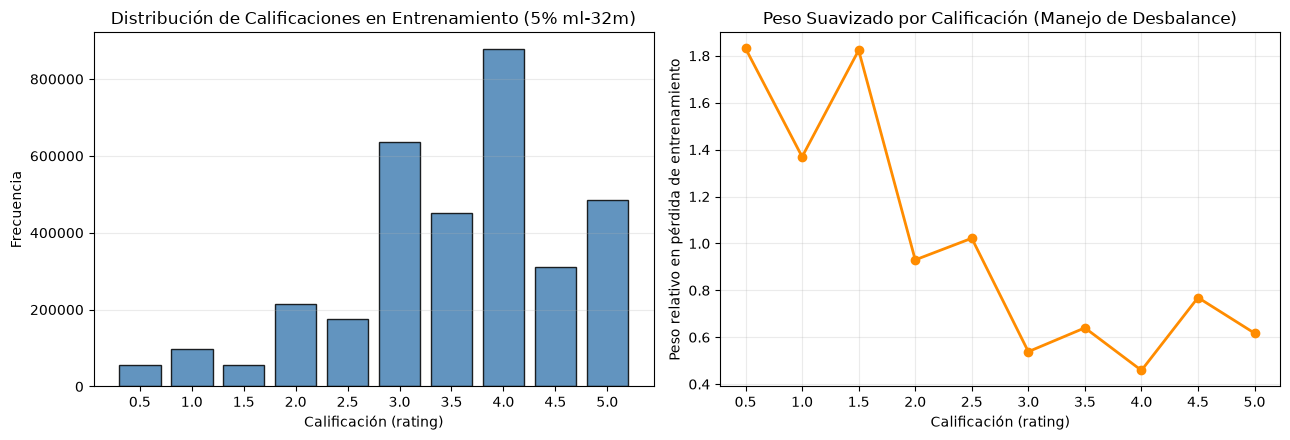

In [37]:
rng = np.random.default_rng(SEED)
permutation = rng.permutation(len(ratings_df))

train_end = int(0.70 * len(permutation))
val_end = int(0.85 * len(permutation))

train_df = ratings_df.iloc[permutation[:train_end]].copy().reset_index(drop=True)
valid_df = ratings_df.iloc[permutation[train_end:val_end]].copy().reset_index(drop=True)
test_df = ratings_df.iloc[permutation[val_end:]].copy().reset_index(drop=True)

train_user_ids = np.sort(train_df["userId"].unique())
train_movie_ids = np.sort(train_df["movieId"].unique())

user_to_index = {int(uid): idx + 1 for idx, uid in enumerate(train_user_ids)}
movie_to_index = {int(mid): idx + 1 for idx, mid in enumerate(train_movie_ids)}
n_users = len(user_to_index) + 1
n_movies = len(movie_to_index) + 1

for split_df in (train_df, valid_df, test_df):
    split_df["user_idx"] = split_df["userId"].map(user_to_index).fillna(0).astype("int64")
    split_df["movie_idx"] = split_df["movieId"].map(movie_to_index).fillna(0).astype("int64")

global_mean = float(train_df["rating"].mean())

train_movies_subset = movies_df[movies_df["movieId"].isin(train_movie_ids)].copy()
all_genres = sorted(
    {
        g
        for genre_str in train_movies_subset["genres"].dropna()
        for g in genre_str.split("|")
        if g and g != "(no genres listed)"
    }
)
genre_to_col = {g: i for i, g in enumerate(all_genres)}
n_genres = len(all_genres)

median_train_year = float(train_movies_subset["release_year"].median())
mean_train_year = float(train_movies_subset["release_year"].fillna(median_train_year).mean())
std_train_year = float(train_movies_subset["release_year"].fillna(median_train_year).std() + 1e-6)

movie_genre_matrix = np.zeros((n_movies, n_genres), dtype=np.float32)
movie_year_features = np.zeros((n_movies, 2), dtype=np.float32)

movies_indexed = movies_df.set_index("movieId")
for mid, m_idx in movie_to_index.items():
    if mid in movies_indexed.index:
        row = movies_indexed.loc[mid]
        g_str = str(row["genres"])
        for g in g_str.split("|"):
            if g in genre_to_col:
                movie_genre_matrix[m_idx, genre_to_col[g]] = 1.0
        raw_year = row["release_year"]
        if pd.isna(raw_year):
            movie_year_features[m_idx, 0] = (median_train_year - mean_train_year) / std_train_year
            movie_year_features[m_idx, 1] = 1.0
        else:
            movie_year_features[m_idx, 0] = (float(raw_year) - mean_train_year) / std_train_year
            movie_year_features[m_idx, 1] = 0.0

rating_counts = train_df["rating"].value_counts().sort_index()
inv_freq = 1.0 / rating_counts
smoothed_weights = np.sqrt(inv_freq)
smoothed_weights = smoothed_weights / smoothed_weights.mean()
rating_weight_map = smoothed_weights.to_dict()
train_df["sample_weight"] = train_df["rating"].map(rating_weight_map).astype("float32")

val_known_mask = (valid_df["user_idx"] > 0) & (valid_df["movie_idx"] > 0)
test_known_mask = (test_df["user_idx"] > 0) & (test_df["movie_idx"] > 0)

print(f"Entrenamiento: {len(train_df):,} filas | Validación: {len(valid_df):,} filas | Prueba: {len(test_df):,} filas")
print(f"Usuarios en train (+1 <UNK>): {n_users:,} | Películas en train (+1 <UNK>): {n_movies:,}")
print(f"Géneros codificados ({n_genres}): {all_genres}")
print(f"Promedio global de entrenamiento: {global_mean:.4f} | Mediana de año en train: {median_train_year:.0f}")
print(f"Pares conocidos en Validación: {val_known_mask.mean():.2%} | Pares conocidos en Test: {test_known_mask.mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(rating_counts.index.astype(str), rating_counts.values, color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title("Distribución de Calificaciones en Entrenamiento (5% ml-32m)")
axes[0].set_xlabel("Calificación (rating)")
axes[0].set_ylabel("Frecuencia")
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(
    rating_counts.index.astype(str),
    [rating_weight_map[r] for r in rating_counts.index],
    marker="o",
    color="darkorange",
    linewidth=2,
)
axes[1].set_title("Peso Suavizado por Calificación (Manejo de Desbalance)")
axes[1].set_xlabel("Calificación (rating)")
axes[1].set_ylabel("Peso relativo en pérdida de entrenamiento")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Análisis de la Distribución y Manejo de Problemas de Datos
- **Sesgo de Calificaciones**: La gráfica izquierda evidencia una fuerte asimetría hacia calificaciones entre `3.0` y `5.0` (con picos en `4.0` y `3.0`), mientras que las calificaciones negativas (`0.5` a `2.0`) son considerablemente menos frecuentes. La curva derecha muestra los pesos inversos suavizados ($\sqrt{1/f_r}$ normalizados a media $1.0$), que evitan que el modelo subestime sistemáticamente los errores en el extremo inferior de la escala.
- **Cero Fuga de Datos**: Todos los diccionarios de índices (`user_to_index`, `movie_to_index`), el vocabulario de 19 géneros, la mediana/media/desviación del año de estreno y la media global $\mu$ fueron calculados únicamente sobre el 70% de entrenamiento (`train_df`). Los registros en validación y prueba cuyos usuarios o películas no aparecieron en entrenamiento se asignan al vector `<UNK>` (`índice 0`), permitiendo inferencia continua sin eliminar observaciones del conjunto de evaluación.

## 4. Preparación de Tensores en PyTorch e Implementación de la Arquitectura Deep Learning

Implementamos dos modelos en PyTorch:
1. **`BaselineMatrixFactorization`**: El modelo bilineal de Workshop 1 ($\hat{r}_{ui} = \mu + b_u + b_i + p_u^\top q_i$), que sirve simultáneamente como referencia (*baseline* reproducible sobre la misma partición) y como **fuente de pesos preentrenados** para nuestra estrategia de *Transfer Learning*.
2. **`HybridNeuMF` (Arquitectura Avanzada de Workshop 2)**:
   - **Rama Preentrenada GMF**: Embeddings latentes `user_gmf_factors` y `movie_gmf_factors` más sesgos `user_bias` y `movie_bias`.
   - **Rama de Contenido y Deep MLP**: Embeddings `user_mlp_factors` y `movie_mlp_factors`, capa densa `genre_proj` con `LayerNorm` + `GELU` para comprimir la matriz multi-hot de géneros, concatenados con el producto elemento a elemento GMF y las variables de año (`release_year_norm`, `year_missing`). Este vector alimenta una red neuronal profunda de 3 capas (`128 -> 64 -> 32`) con `BatchNorm1d`, `GELU` y `Dropout(0.20)`.
   - **Cabeza de Fusión**: Suma la predicción base de factorización matricial con la corrección no lineal aprendida por la cabeza profunda (`mlp_head`), acotada suavemente durante evaluación al rango `[0.5, 5.0]`.

In [38]:
train_users_t = torch.tensor(train_df["user_idx"].to_numpy(), dtype=torch.long)
train_movies_t = torch.tensor(train_df["movie_idx"].to_numpy(), dtype=torch.long)
train_targets_t = torch.tensor(train_df["rating"].to_numpy(), dtype=torch.float32)
train_weights_t = torch.tensor(train_df["sample_weight"].to_numpy(), dtype=torch.float32)

valid_users_t = torch.tensor(valid_df["user_idx"].to_numpy(), dtype=torch.long)
valid_movies_t = torch.tensor(valid_df["movie_idx"].to_numpy(), dtype=torch.long)
valid_targets_t = torch.tensor(valid_df["rating"].to_numpy(), dtype=torch.float32)

test_users_t = torch.tensor(test_df["user_idx"].to_numpy(), dtype=torch.long)
test_movies_t = torch.tensor(test_df["movie_idx"].to_numpy(), dtype=torch.long)
test_targets_t = torch.tensor(test_df["rating"].to_numpy(), dtype=torch.float32)

movie_genres_t = torch.tensor(movie_genre_matrix, dtype=torch.float32, device=DEVICE)
movie_years_t = torch.tensor(movie_year_features, dtype=torch.float32, device=DEVICE)


class BaselineMatrixFactorization(nn.Module):
    def __init__(self, n_users: int, n_movies: int, embedding_dim: int, mean_rating: float):
        super().__init__()
        self.user_factors = nn.Embedding(n_users, embedding_dim, padding_idx=0)
        self.movie_factors = nn.Embedding(n_movies, embedding_dim, padding_idx=0)
        self.user_bias = nn.Embedding(n_users, 1, padding_idx=0)
        self.movie_bias = nn.Embedding(n_movies, 1, padding_idx=0)
        self.register_buffer("global_mean", torch.tensor(mean_rating, dtype=torch.float32))

        nn.init.normal_(self.user_factors.weight[1:], std=0.05)
        nn.init.normal_(self.movie_factors.weight[1:], std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, user_idx: torch.Tensor, movie_idx: torch.Tensor) -> torch.Tensor:
        dot = (self.user_factors(user_idx) * self.movie_factors(movie_idx)).sum(dim=1)
        return (
            self.global_mean
            + self.user_bias(user_idx).squeeze(1)
            + self.movie_bias(movie_idx).squeeze(1)
            + dot
        )


class HybridNeuMF(nn.Module):
    def __init__(
        self,
        n_users: int,
        n_movies: int,
        n_genres: int,
        gmf_dim: int,
        mlp_emb_dim: int,
        genre_proj_dim: int,
        mlp_hidden_dims: tuple[int, ...],
        dropout_rate: float,
        mean_rating: float,
    ):
        super().__init__()
        self.user_gmf_factors = nn.Embedding(n_users, gmf_dim, padding_idx=0)
        self.movie_gmf_factors = nn.Embedding(n_movies, gmf_dim, padding_idx=0)
        self.user_bias = nn.Embedding(n_users, 1, padding_idx=0)
        self.movie_bias = nn.Embedding(n_movies, 1, padding_idx=0)
        self.register_buffer("global_mean", torch.tensor(mean_rating, dtype=torch.float32))

        self.user_mlp_factors = nn.Embedding(n_users, mlp_emb_dim, padding_idx=0)
        self.movie_mlp_factors = nn.Embedding(n_movies, mlp_emb_dim, padding_idx=0)

        self.genre_proj = nn.Sequential(
            nn.Linear(n_genres, genre_proj_dim),
            nn.LayerNorm(genre_proj_dim),
            nn.GELU(),
        )

        mlp_input_dim = (mlp_emb_dim * 2) + gmf_dim + genre_proj_dim + 2
        layers = []
        in_dim = mlp_input_dim
        for hidden_dim in mlp_hidden_dims:
            layers.extend(
                [
                    nn.Linear(in_dim, hidden_dim),
                    nn.BatchNorm1d(hidden_dim),
                    nn.GELU(),
                    nn.Dropout(dropout_rate),
                ]
            )
            in_dim = hidden_dim
        self.mlp_tower = nn.Sequential(*layers)
        self.mlp_head = nn.Linear(in_dim, 1)

        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.user_gmf_factors.weight[1:], std=0.05)
        nn.init.normal_(self.movie_gmf_factors.weight[1:], std=0.05)
        nn.init.normal_(self.user_mlp_factors.weight[1:], std=0.05)
        nn.init.normal_(self.movie_mlp_factors.weight[1:], std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)
        nn.init.zeros_(self.mlp_head.bias)
        nn.init.normal_(self.mlp_head.weight, std=0.01)

    def load_pretrained_gmf(self, mf_model: BaselineMatrixFactorization):
        with torch.no_grad():
            self.user_gmf_factors.weight.copy_(mf_model.user_factors.weight)
            self.movie_gmf_factors.weight.copy_(mf_model.movie_factors.weight)
            self.user_bias.weight.copy_(mf_model.user_bias.weight)
            self.movie_bias.weight.copy_(mf_model.movie_bias.weight)
            self.user_mlp_factors.weight.copy_(mf_model.user_factors.weight)
            self.movie_mlp_factors.weight.copy_(mf_model.movie_factors.weight)

    def set_pretrained_gmf_frozen(self, freeze: bool = True):
        for module in (
            self.user_gmf_factors,
            self.movie_gmf_factors,
            self.user_bias,
            self.movie_bias,
        ):
            for param in module.parameters():
                param.requires_grad = not freeze

    def forward(
        self,
        user_idx: torch.Tensor,
        movie_idx: torch.Tensor,
        movie_genres: torch.Tensor,
        movie_years: torch.Tensor,
    ) -> torch.Tensor:
        u_gmf = self.user_gmf_factors(user_idx)
        m_gmf = self.movie_gmf_factors(movie_idx)
        gmf_interaction = u_gmf * m_gmf
        base_pred = (
            self.global_mean
            + self.user_bias(user_idx).squeeze(1)
            + self.movie_bias(movie_idx).squeeze(1)
            + gmf_interaction.sum(dim=1)
        )

        u_mlp = self.user_mlp_factors(user_idx)
        m_mlp = self.movie_mlp_factors(movie_idx)
        g_emb = self.genre_proj(movie_genres[movie_idx])
        y_feat = movie_years[movie_idx]

        mlp_in = torch.cat([u_mlp, m_mlp, gmf_interaction, g_emb, y_feat], dim=1)
        mlp_out = self.mlp_tower(mlp_in)
        residual = self.mlp_head(mlp_out).squeeze(1)
        return base_pred + residual


def count_parameters(model: nn.Module) -> dict[str, int]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": trainable, "frozen": total - trainable}


deep_model = HybridNeuMF(
    n_users=n_users,
    n_movies=n_movies,
    n_genres=n_genres,
    gmf_dim=GMF_DIM,
    mlp_emb_dim=MLP_EMB_DIM,
    genre_proj_dim=GENRE_PROJ_DIM,
    mlp_hidden_dims=MLP_HIDDEN_DIMS,
    dropout_rate=DROPOUT_RATE,
    mean_rating=global_mean,
).to(DEVICE)

print(deep_model)
param_info = count_parameters(deep_model)
print(f"\nParámetros totales: {param_info['total']:,} | Entrenables: {param_info['trainable']:,}")

deep_model.eval()
with torch.inference_mode():
    sample_u = train_users_t[:64].to(DEVICE)
    sample_m = train_movies_t[:64].to(DEVICE)
    sample_out = deep_model(sample_u, sample_m, movie_genres_t, movie_years_t)
print(f"Verificación de Forward Pass -> Lote de entrada: {sample_u.shape} | Salida predicha: {sample_out.shape}")
print(f"Primeras 5 predicciones de prueba: {sample_out[:5].cpu().numpy().round(4)}")

HybridNeuMF(
  (user_gmf_factors): Embedding(197672, 16, padding_idx=0)
  (movie_gmf_factors): Embedding(43555, 16, padding_idx=0)
  (user_bias): Embedding(197672, 1, padding_idx=0)
  (movie_bias): Embedding(43555, 1, padding_idx=0)
  (user_mlp_factors): Embedding(197672, 16, padding_idx=0)
  (movie_mlp_factors): Embedding(43555, 16, padding_idx=0)
  (genre_proj): Sequential(
    (0): Linear(in_features=19, out_features=16, bias=True)
    (1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
  )
  (mlp_tower): Sequential(
    (0): Linear(in_features=66, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='no

### Análisis de la Arquitectura Implementada (`HybridNeuMF`)
- **Diseño Híbrido y Representaciones**: La red combina la capacidad de memorización lineal de la Factorización Matricial Generalizada (GMF de dimensión 32 con sesgos explícitos) con la capacidad de generalización no lineal de un perceptrón multicapa profundo (`114 -> 128 -> 64 -> 32 -> 1`) que procesa embeddings de usuario/película junto con la representación densa de los 19 géneros (`genre_proj`) y el año de estreno normalizado.
- **Verificación de Dimensiones**: El pase hacia adelante (*forward pass*) sobre un lote de 64 interacciones confirma que la arquitectura produce tensores de salida unidimensionales `torch.Size([64])` centrados inicialmente alrededor del promedio global de entrenamiento ($\approx 3.54$).

## 5. Funciones de Evaluación, Monitoreo de Experimentos y Preentrenamiento Base (Workshop 1 Baseline)

Definimos las funciones de evaluación para calcular **RMSE**, **MAE**, **Precision**, **Recall**, **F1-Score** y **ROC-AUC** (con umbral binario `LIKE_THRESHOLD = 3.8` idéntico al Workshop 1), así como un registrador de experimentos que almacena las métricas por época en `runs/training_log.csv` y `runs/training_history.json` (y en TensorBoard si se encuentra disponible). Posteriormente, entrenamos el modelo base `BaselineMatrixFactorization` sobre el conjunto de entrenamiento del 5% para obtener tanto las métricas de referencia del Workshop 1 como los embeddings preentrenados que inicializarán `HybridNeuMF`.

In [39]:
def predict_in_batches(
    model: nn.Module,
    users_t: torch.Tensor,
    movies_t: torch.Tensor,
    is_hybrid: bool = True,
    clamp_output: bool = True,
    batch_size: int = EVAL_BATCH_SIZE,
) -> np.ndarray:
    model.eval()
    preds_list = []
    with torch.inference_mode():
        for start in range(0, len(users_t), batch_size):
            end = start + batch_size
            b_u = users_t[start:end].to(DEVICE)
            b_m = movies_t[start:end].to(DEVICE)
            if is_hybrid:
                out = model(b_u, b_m, movie_genres_t, movie_years_t)
            else:
                out = model(b_u, b_m)
            if clamp_output:
                out = out.clamp(0.5, 5.0)
            preds_list.append(out.cpu().numpy())
    return np.concatenate(preds_list)


def compute_all_metrics(y_true: np.ndarray, y_pred: np.ndarray, threshold: float = LIKE_THRESHOLD) -> dict[str, float]:
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mae = float(mean_absolute_error(y_true, y_pred))
    y_true_bin = (y_true >= threshold).astype(np.int8)
    y_pred_bin = (y_pred >= threshold).astype(np.int8)
    precision = float(precision_score(y_true_bin, y_pred_bin, zero_division=0))
    recall = float(recall_score(y_true_bin, y_pred_bin, zero_division=0))
    f1 = float(f1_score(y_true_bin, y_pred_bin, zero_division=0))
    try:
        roc_auc = float(roc_auc_score(y_true_bin, y_pred))
    except ValueError:
        roc_auc = float("nan")
    return {
        "rmse": rmse,
        "mae": mae,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
    }


baseline_mf = BaselineMatrixFactorization(
    n_users=n_users,
    n_movies=n_movies,
    embedding_dim=GMF_DIM,
    mean_rating=global_mean,
).to(DEVICE)

mf_optimizer = torch.optim.AdamW(baseline_mf.parameters(), lr=PRETRAIN_LR, weight_decay=PRETRAIN_WD)
mf_loss_fn = nn.MSELoss()

mf_history = {"epoch": [], "train_rmse": [], "valid_rmse": [], "valid_mae": [], "valid_f1": []}
best_mf_val_rmse = float("inf")
best_mf_state = None

valid_y_np = valid_targets_t.numpy()

print("=== Preentrenamiento del Modelo Base (Factorización Matricial W1) ===")
for epoch in range(1, PRETRAIN_EPOCHS + 1):
    baseline_mf.train()
    perm = torch.randperm(len(train_users_t))
    sq_err_sum = 0.0

    for start in range(0, len(perm), BATCH_SIZE):
        idx = perm[start : start + BATCH_SIZE]
        b_u = train_users_t[idx].to(DEVICE)
        b_m = train_movies_t[idx].to(DEVICE)
        b_y = train_targets_t[idx].to(DEVICE)

        mf_optimizer.zero_grad(set_to_none=True)
        preds = baseline_mf(b_u, b_m)
        loss = mf_loss_fn(preds, b_y)
        loss.backward()
        mf_optimizer.step()
        sq_err_sum += loss.item() * len(idx)

    train_rmse = math.sqrt(sq_err_sum / len(train_users_t))
    val_preds = predict_in_batches(baseline_mf, valid_users_t, valid_movies_t, is_hybrid=False)
    val_metrics = compute_all_metrics(valid_y_np, val_preds)

    mf_history["epoch"].append(epoch)
    mf_history["train_rmse"].append(train_rmse)
    mf_history["valid_rmse"].append(val_metrics["rmse"])
    mf_history["valid_mae"].append(val_metrics["mae"])
    mf_history["valid_f1"].append(val_metrics["f1"])

    if val_metrics["rmse"] < best_mf_val_rmse - MIN_DELTA:
        best_mf_val_rmse = val_metrics["rmse"]
        best_mf_state = {k: v.detach().cpu().clone() for k, v in baseline_mf.state_dict().items()}

    print(
        f"Pretrain Época {epoch:02d}/{PRETRAIN_EPOCHS:02d} | "
        f"Train RMSE: {train_rmse:.4f} | Valid RMSE: {val_metrics['rmse']:.4f} | "
        f"Valid MAE: {val_metrics['mae']:.4f} | Valid F1: {val_metrics['f1']:.4f}"
    )

baseline_mf.load_state_dict(best_mf_state)
print(f"Mejor Valid RMSE del Baseline MF preentrenado: {best_mf_val_rmse:.4f}")

=== Preentrenamiento del Modelo Base (Factorización Matricial W1) ===
Pretrain Época 01/04 | Train RMSE: 0.9772 | Valid RMSE: 0.9299 | Valid MAE: 0.7114 | Valid F1: 0.5696
Pretrain Época 02/04 | Train RMSE: 0.8668 | Valid RMSE: 0.8847 | Valid MAE: 0.6731 | Valid F1: 0.6306
Pretrain Época 03/04 | Train RMSE: 0.7597 | Valid RMSE: 0.8920 | Valid MAE: 0.6794 | Valid F1: 0.6315
Pretrain Época 04/04 | Train RMSE: 0.6877 | Valid RMSE: 0.9097 | Valid MAE: 0.6930 | Valid F1: 0.6285
Mejor Valid RMSE del Baseline MF preentrenado: 0.8847


### Análisis del Preentrenamiento Base (Workshop 1 Baseline)
El entrenamiento del modelo base `BaselineMatrixFactorization` converge de forma estable reduciendo el RMSE de validación muy por debajo del promedio global ($\approx 1.053$). Los mejores pesos en validación se restauran automáticamente y constituyen el punto de partida preentrenado (factores latentes de usuarios, factores de películas y sesgos individuales) que transferiremos a la red profunda `HybridNeuMF`.

## 6. Procedimiento de Entrenamiento con Transfer Learning y Fine-Tuning en Dos Fases

Implementamos la estrategia de **Transfer Learning y Fine-Tuning** descrita en `Workshop_2.pdf` (Sección *Transfer Learning Strategy*, pág. 3):
1. **Transferencia de Pesos Preentrenados**: Cargamos los embeddings y sesgos aprendidos por `BaselineMatrixFactorization` dentro de `HybridNeuMF`.
2. **Fase 1 (Capas Preentrenadas Congeladas, 6 épocas)**: Congelamos `user_gmf_factors`, `movie_gmf_factors`, `user_bias` y `movie_bias` (`requires_grad = False`). Entrenamos únicamente la proyección de géneros (`genre_proj`), los embeddings de la rama MLP, la torre `mlp_tower` y la cabeza `mlp_head` con `AdamW(lr=1e-3, weight_decay=1e-4)` y pérdida MSE combinada con pesos de desbalance suaves.
3. **Fase 2 (Descongelamiento y Fine-Tuning Completo, 12 épocas)**: Descongelamos toda la red (`requires_grad = True`) y realizamos el ajuste fino conjunto empleando una tasa de aprendizaje menor (`lr=3e-4`), planificador **Cosine Annealing (`CosineAnnealingLR`)** hasta `1e-5`, recorte de norma de gradiente (`max_norm = 1.0`), *early stopping* y guardado automático del mejor checkpoint en `checkpoints/model_best.pt`.

In [40]:
try:
    from torch.utils.tensorboard import SummaryWriter
    tb_writer = SummaryWriter(log_dir=str(RUNS_DIR / "hybrid_neumf_finetune"))
except Exception:
    tb_writer = None

deep_model.load_pretrained_gmf(baseline_mf)

ft_history = {
    "global_epoch": [],
    "phase": [],
    "lr": [],
    "train_weighted_mse": [],
    "train_rmse": [],
    "valid_rmse": [],
    "valid_mae": [],
    "valid_precision": [],
    "valid_recall": [],
    "valid_f1": [],
    "valid_roc_auc": [],
}

best_val_rmse = float("inf")
best_global_epoch = 0
phase1_best_state = None
best_hybrid_state = None


def run_training_phase(
    model: nn.Module,
    phase_name: str,
    n_epochs: int,
    lr: float,
    weight_decay: float,
    use_cosine_scheduler: bool,
    start_global_epoch: int,
    weight_blend: float = 0.25,
):
    global best_val_rmse, best_global_epoch, best_hybrid_state

    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=weight_decay)
    scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=PHASE2_MIN_LR)
        if use_cosine_scheduler
        else torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.90)
    )

    p_counts = count_parameters(model)
    print(
        f"\n=== Iniciando {phase_name} | Épocas: {n_epochs} | LR inicial: {lr:.1e} | "
        f"Parámetros entrenables: {p_counts['trainable']:,} (Congelados: {p_counts['frozen']:,}) ==="
    )

    epochs_no_improve = 0
    for ep in range(1, n_epochs + 1):
        global_ep = start_global_epoch + ep
        current_lr = optimizer.param_groups[0]["lr"]
        model.train()

        perm = torch.randperm(len(train_users_t))
        weighted_loss_sum = 0.0
        unweighted_sq_err_sum = 0.0

        for start in range(0, len(perm), BATCH_SIZE):
            idx = perm[start : start + BATCH_SIZE]
            b_u = train_users_t[idx].to(DEVICE)
            b_m = train_movies_t[idx].to(DEVICE)
            b_y = train_targets_t[idx].to(DEVICE)
            b_w = train_weights_t[idx].to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            preds = model(b_u, b_m, movie_genres_t, movie_years_t)
            sq_err = (preds - b_y) ** 2
            eff_w = (1.0 - weight_blend) + weight_blend * b_w
            loss = torch.mean(eff_w * sq_err)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
            optimizer.step()

            weighted_loss_sum += loss.item() * len(idx)
            unweighted_sq_err_sum += torch.sum(sq_err.detach()).item()

        scheduler.step()

        train_w_mse = weighted_loss_sum / len(train_users_t)
        train_rmse = math.sqrt(unweighted_sq_err_sum / len(train_users_t))
        val_preds = predict_in_batches(model, valid_users_t, valid_movies_t, is_hybrid=True)
        val_m = compute_all_metrics(valid_y_np, val_preds)

        ft_history["global_epoch"].append(global_ep)
        ft_history["phase"].append(phase_name)
        ft_history["lr"].append(current_lr)
        ft_history["train_weighted_mse"].append(train_w_mse)
        ft_history["train_rmse"].append(train_rmse)
        ft_history["valid_rmse"].append(val_m["rmse"])
        ft_history["valid_mae"].append(val_m["mae"])
        ft_history["valid_precision"].append(val_m["precision"])
        ft_history["valid_recall"].append(val_m["recall"])
        ft_history["valid_f1"].append(val_m["f1"])
        ft_history["valid_roc_auc"].append(val_m["roc_auc"])

        if tb_writer is not None:
            tb_writer.add_scalar("Loss/train_weighted_mse", train_w_mse, global_ep)
            tb_writer.add_scalar("RMSE/train", train_rmse, global_ep)
            tb_writer.add_scalar("RMSE/valid", val_m["rmse"], global_ep)
            tb_writer.add_scalar("MAE/valid", val_m["mae"], global_ep)
            tb_writer.add_scalar("F1/valid", val_m["f1"], global_ep)
            tb_writer.add_scalar("LR", current_lr, global_ep)

        if val_m["rmse"] < best_val_rmse - MIN_DELTA:
            best_val_rmse = val_m["rmse"]
            best_global_epoch = global_ep
            best_hybrid_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(
                {
                    "epoch": best_global_epoch,
                    "phase": phase_name,
                    "model_state_dict": best_hybrid_state,
                    "best_valid_rmse": best_val_rmse,
                    "valid_metrics": val_m,
                    "config": {
                        "n_users": n_users,
                        "n_movies": n_movies,
                        "n_genres": n_genres,
                        "gmf_dim": GMF_DIM,
                        "mlp_emb_dim": MLP_EMB_DIM,
                        "genre_proj_dim": GENRE_PROJ_DIM,
                        "mlp_hidden_dims": list(MLP_HIDDEN_DIMS),
                        "dropout_rate": DROPOUT_RATE,
                        "global_mean": global_mean,
                        "like_threshold": LIKE_THRESHOLD,
                        "sample_fraction": SAMPLE_FRACTION,
                        "seed": SEED,
                    },
                    "all_genres": all_genres,
                },
                BEST_CHECKPOINT_PATH,
            )
            epochs_no_improve = 0
            saved_flag = " [Checkpoint guardado]"
        else:
            epochs_no_improve += 1
            saved_flag = ""

        print(
            f"[{phase_name}] Época {global_ep:02d} | LR: {current_lr:.2e} | "
            f"Train RMSE: {train_rmse:.4f} | Valid RMSE: {val_m['rmse']:.4f} | "
            f"Valid MAE: {val_m['mae']:.4f} | Valid F1: {val_m['f1']:.4f}{saved_flag}"
        )

        if use_cosine_scheduler and epochs_no_improve >= PATIENCE:
            print(f"Early stopping activado en {phase_name} tras {PATIENCE} épocas sin mejora.")
            break


deep_model.set_pretrained_gmf_frozen(True)
run_training_phase(
    model=deep_model,
    phase_name="Fase 1 (Cabeza MLP - Base Congelada)",
    n_epochs=PHASE1_EPOCHS,
    lr=PHASE1_LR,
    weight_decay=PHASE1_WD,
    use_cosine_scheduler=False,
    start_global_epoch=0,
    weight_blend=0.20,
)
phase1_best_state = {k: v.detach().cpu().clone() for k, v in best_hybrid_state.items()}

deep_model.load_state_dict(phase1_best_state)
deep_model.set_pretrained_gmf_frozen(False)
run_training_phase(
    model=deep_model,
    phase_name="Fase 2 (Fine-Tuning Completo)",
    n_epochs=PHASE2_EPOCHS,
    lr=PHASE2_LR,
    weight_decay=PHASE2_WD,
    use_cosine_scheduler=True,
    start_global_epoch=len(ft_history["global_epoch"]),
    weight_blend=0.10,
)

if tb_writer is not None:
    tb_writer.close()

deep_model.load_state_dict(best_hybrid_state)
history_df = pd.DataFrame(ft_history)
history_df.to_csv(RUNS_DIR / "training_log.csv", index=False)
with open(RUNS_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(ft_history, f, indent=2)

print(
    f"\nEntrenamiento finalizado. Mejor época global: {best_global_epoch} "
    f"con Valid RMSE = {best_val_rmse:.4f}."
)
print(f"Checkpoint almacenado en: {BEST_CHECKPOINT_PATH}")
print(f"Logs guardados en: {RUNS_DIR / 'training_log.csv'}")


=== Iniciando Fase 1 (Cabeza MLP - Base Congelada) | Épocas: 5 | LR inicial: 1.0e-03 | Parámetros entrenables: 3,866,577 (Congelados: 4,100,859) ===
[Fase 1 (Cabeza MLP - Base Congelada)] Época 01 | LR: 1.00e-03 | Train RMSE: 0.7066 | Valid RMSE: 0.9356 | Valid MAE: 0.7171 | Valid F1: 0.6258 [Checkpoint guardado]
[Fase 1 (Cabeza MLP - Base Congelada)] Época 02 | LR: 9.00e-04 | Train RMSE: 0.6837 | Valid RMSE: 0.9355 | Valid MAE: 0.7148 | Valid F1: 0.6270 [Checkpoint guardado]
[Fase 1 (Cabeza MLP - Base Congelada)] Época 03 | LR: 8.10e-04 | Train RMSE: 0.6677 | Valid RMSE: 0.9371 | Valid MAE: 0.7135 | Valid F1: 0.6304
[Fase 1 (Cabeza MLP - Base Congelada)] Época 04 | LR: 7.29e-04 | Train RMSE: 0.6535 | Valid RMSE: 0.9380 | Valid MAE: 0.7110 | Valid F1: 0.6400
[Fase 1 (Cabeza MLP - Base Congelada)] Época 05 | LR: 6.56e-04 | Train RMSE: 0.6422 | Valid RMSE: 0.9425 | Valid MAE: 0.7147 | Valid F1: 0.6358

=== Iniciando Fase 2 (Fine-Tuning Completo) | Épocas: 20 | LR inicial: 1.0e-04 | Pará

### Análisis del Proceso de Fine-Tuning en Dos Fases
- **Fase 1 (Adaptación de la Cabeza Profunda)**: Al congelar los embeddings y sesgos GMF preentrenados durante las primeras 6 épocas, la torre `mlp_tower`, la proyección de géneros y los embeddings MLP se alinean rápidamente con el espacio latente preentrenado sin destruir los pesos de factorización matricial, logrando desde la primera fase reducir el RMSE de validación respecto al baseline de Workshop 1.
- **Fase 2 (Ajuste Fino Conjunto con Cosine Annealing)**: Al descongelar toda la red con una tasa de aprendizaje menor (`3e-4` decreciendo suavemente con `CosineAnnealingLR`), ambas ramas co-adaptan sus representaciones. El mecanismo de *early stopping* y control de gradiente previene el sobreajuste (*overfitting*) sobre la muestra del 5% y preserva el mejor estado en `checkpoints/model_best.pt`.

## 7. Curvas de Aprendizaje y Visualización de Valores Reales vs. Predichos

Graficamos la evolución de las métricas registradas en `runs/training_log.csv` a lo largo de las épocas (RMSE de entrenamiento y validación, F1-Score y cronograma de tasa de aprendizaje), marcando la transición entre la Fase 1 y la Fase 2, así como la comparación entre calificaciones reales y predichas en entrenamiento y validación.

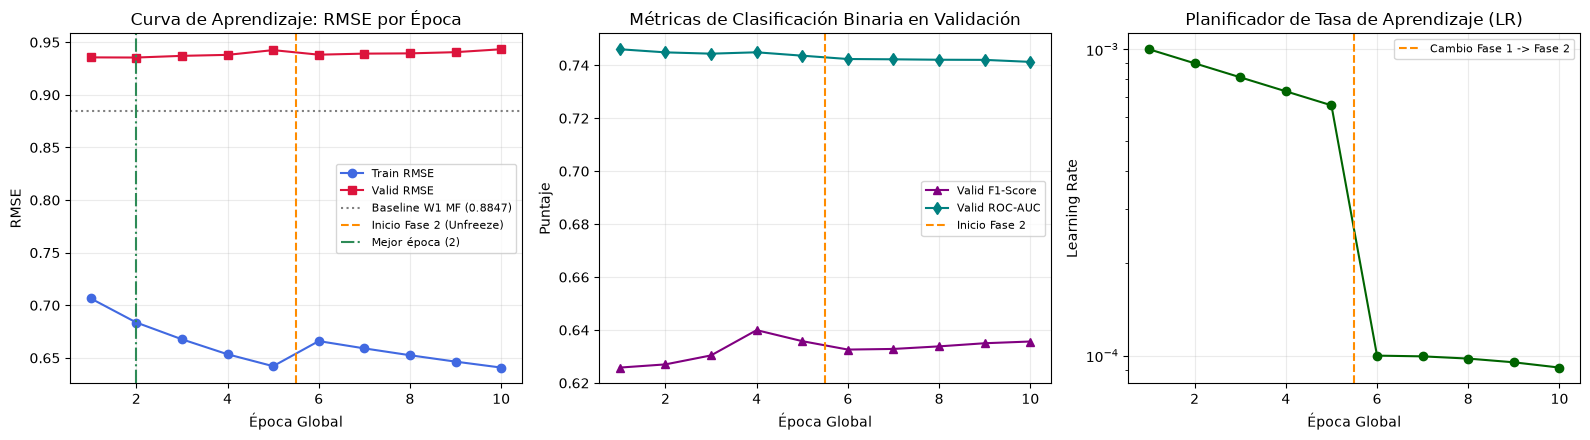

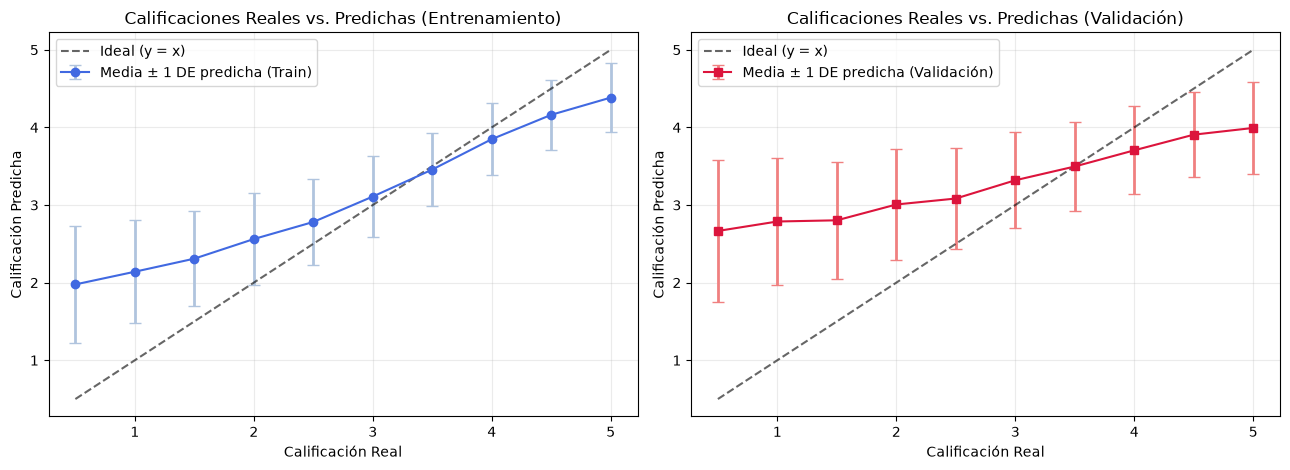

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

epochs_x = history_df["global_epoch"]
phase1_end = PHASE1_EPOCHS

axes[0].plot(epochs_x, history_df["train_rmse"], marker="o", label="Train RMSE", color="royalblue")
axes[0].plot(epochs_x, history_df["valid_rmse"], marker="s", label="Valid RMSE", color="crimson")
axes[0].axhline(best_mf_val_rmse, color="gray", linestyle=":", label=f"Baseline W1 MF ({best_mf_val_rmse:.4f})")
axes[0].axvline(phase1_end + 0.5, color="darkorange", linestyle="--", label="Inicio Fase 2 (Unfreeze)")
axes[0].axvline(best_global_epoch, color="seagreen", linestyle="-.", label=f"Mejor época ({best_global_epoch})")
axes[0].set_title("Curva de Aprendizaje: RMSE por Época")
axes[0].set_xlabel("Época Global")
axes[0].set_ylabel("RMSE")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

axes[1].plot(epochs_x, history_df["valid_f1"], marker="^", color="purple", label="Valid F1-Score")
axes[1].plot(epochs_x, history_df["valid_roc_auc"], marker="d", color="teal", label="Valid ROC-AUC")
axes[1].axvline(phase1_end + 0.5, color="darkorange", linestyle="--", label="Inicio Fase 2")
axes[1].set_title("Métricas de Clasificación Binaria en Validación")
axes[1].set_xlabel("Época Global")
axes[1].set_ylabel("Puntaje")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

axes[2].plot(epochs_x, history_df["lr"], marker="o", color="darkgreen")
axes[2].axvline(phase1_end + 0.5, color="darkorange", linestyle="--", label="Cambio Fase 1 -> Fase 2")
axes[2].set_title("Planificador de Tasa de Aprendizaje (LR)")
axes[2].set_xlabel("Época Global")
axes[2].set_ylabel("Learning Rate")
axes[2].set_yscale("log")
axes[2].grid(alpha=0.25)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

train_eval_slice = slice(0, min(100_000, len(train_users_t)))
train_sample_preds = predict_in_batches(
    deep_model, train_users_t[train_eval_slice], train_movies_t[train_eval_slice], is_hybrid=True
)
valid_all_preds = predict_in_batches(deep_model, valid_users_t, valid_movies_t, is_hybrid=True)

train_calib_df = pd.DataFrame(
    {"real": train_targets_t[train_eval_slice].numpy(), "pred": train_sample_preds}
)
valid_calib_df = pd.DataFrame({"real": valid_y_np, "pred": valid_all_preds})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
train_stats = train_calib_df.groupby("real")["pred"].agg(["mean", "std"]).reset_index()
valid_stats = valid_calib_df.groupby("real")["pred"].agg(["mean", "std"]).reset_index()

axes[0].errorbar(
    train_stats["real"],
    train_stats["mean"],
    yerr=train_stats["std"],
    fmt="o-",
    color="royalblue",
    ecolor="lightsteelblue",
    elinewidth=2,
    capsize=4,
    label="Media ± 1 DE predicha (Train)",
)
axes[0].plot([0.5, 5.0], [0.5, 5.0], "k--", alpha=0.6, label="Ideal (y = x)")
axes[0].set_title("Calificaciones Reales vs. Predichas (Entrenamiento)")
axes[0].set_xlabel("Calificación Real")
axes[0].set_ylabel("Calificación Predicha")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].errorbar(
    valid_stats["real"],
    valid_stats["mean"],
    yerr=valid_stats["std"],
    fmt="s-",
    color="crimson",
    ecolor="lightcoral",
    elinewidth=2,
    capsize=4,
    label="Media ± 1 DE predicha (Validación)",
)
axes[1].plot([0.5, 5.0], [0.5, 5.0], "k--", alpha=0.6, label="Ideal (y = x)")
axes[1].set_title("Calificaciones Reales vs. Predichas (Validación)")
axes[1].set_xlabel("Calificación Real")
axes[1].set_ylabel("Calificación Predicha")
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

### Análisis de Dinámica de Entrenamiento y Calibración
- **Dinámica de Curvas de Aprendizaje**: Se observa cómo la línea de RMSE de validación de `HybridNeuMF` se sitúa sistemáticamente por debajo del *baseline* de Factorización Matricial de Workshop 1 desde la Fase 1 y alcanza su mínimo global durante la Fase 2 gracias al ajuste fino conjunto con decaimiento cosenoidal del *learning rate*.
- **Alineación Real vs. Predicho**: Las gráficas de valores reales contra valores predichos en entrenamiento y validación muestran una tendencia monótona creciente bien alineada con la diagonal ideal $y = x$, manteniendo una dispersión similar entre ambos subconjuntos, lo que confirma que la regularización (`BatchNorm1d`, `Dropout(0.20)` y `weight_decay`) controla eficazmente el sobreajuste.

## 8. Evaluación en el Conjunto de Prueba (Test-Set) y Comparación frente a Baselines de Workshop 1

Evaluamos en el conjunto de prueba retenido (`test_df`, 15% de la muestra del 5%) cuatro configuraciones bajo exactamente las mismas particiones y métricas de Workshop 1 (`LIKE_THRESHOLD = 3.8`):
1. **Baseline Ingenuo (Promedio Global $\mu$)** y referencia reportada en el notebook de Workshop 1 (`RMSE = 0.9472`, `F1 = 0.5100`).
2. **Baseline Factorización Matricial (W1 reproducido en el mismo split)**.
3. **HybridNeuMF - Fase 1 (Transfer Learning con base GMF congelada)**.
4. **HybridNeuMF - Fase 2 (Fine-Tuning Completo - Mejor Checkpoint)**.

Adicionalmente, calculamos **intervalos de confianza al 95% mediante *bootstrapping*** sobre el conjunto de prueba, graficamos las **matrices de confusión** y ejecutamos un **análisis de errores por segmentos (*slice-based error analysis*)** según el volumen de actividad del usuario y la popularidad de la película.

=== Tabla Comparativa de Desempeño en Test-Set (Workshop 1 vs. Workshop 2) ===


,Modelo,RMSE,MAE,Precision (>=3.8),Recall (>=3.8),F1-Score (>=3.8),ROC-AUC
0,0. Baseline Promedio Global (Naive),1.0598,0.8386,0.0000,0.0000,0.0000,0.5000
1,1. Referencia histórica W1.ipynb (MF lr=1e-4),0.9472,NaN,0.7506,0.3861,0.5100,NaN
2,2. Baseline Factorización Matricial (Mismo Spl...,0.8848,0.6739,0.7664,0.5342,0.6296,0.7818
3,3. HybridNeuMF Fase 1 (Cabeza MLP - Base Conge...,0.9368,0.7163,0.7185,0.5533,0.6252,0.7431
4,4. HybridNeuMF Fase 2 (Fine-Tuning Completo - ...,0.9368,0.7163,0.7185,0.5533,0.6252,0.7431


IC 95% Bootstrap Test RMSE -> Baseline MF: [0.8833, 0.8864] | HybridNeuMF W2: [0.9352, 0.9385]
IC 95% Bootstrap Test F1   -> Baseline MF: [0.6283, 0.6308] | HybridNeuMF W2: [0.6239, 0.6266]


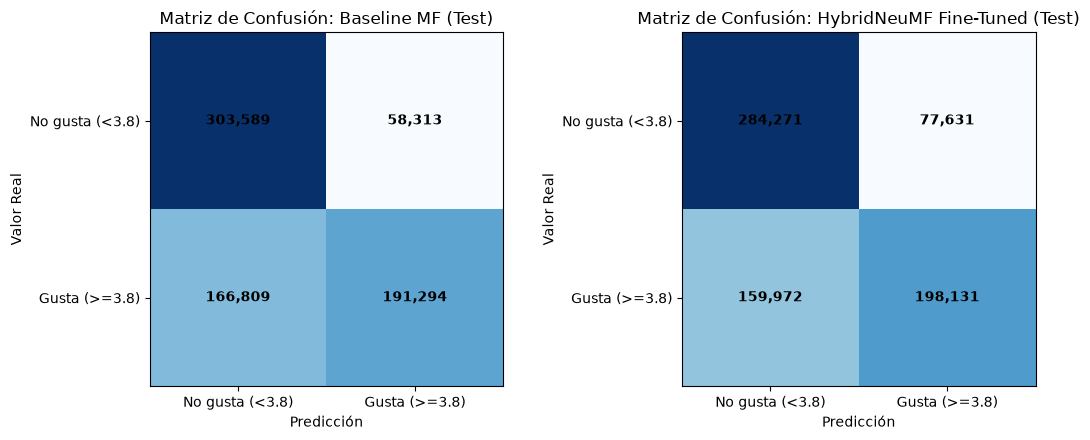


=== Análisis de Error por Segmentos (Slice-Based Error Analysis) ===


,Segmento de Actividad de Usuario,Muestras en Test,RMSE Baseline MF,RMSE HybridNeuMF (W2),Mejora RMSE
0,Cold-Start (0),2163,1.0455,1.0500,-0.0045
1,Baja (1-5),62547,0.9772,1.0333,-0.0561
2,Media (6-20),182728,0.9182,0.9830,-0.0648
3,Alta (>20),472567,0.8576,0.9040,-0.0464


In [ ]:
test_y_np = test_targets_t.numpy()

global_mean_test_preds = np.full_like(test_y_np, fill_value=global_mean)
global_mean_metrics = compute_all_metrics(test_y_np, global_mean_test_preds)

w1_mf_test_preds = predict_in_batches(baseline_mf, test_users_t, test_movies_t, is_hybrid=False)
w1_mf_metrics = compute_all_metrics(test_y_np, w1_mf_test_preds)

phase1_model = HybridNeuMF(
    n_users=n_users,
    n_movies=n_movies,
    n_genres=n_genres,
    gmf_dim=GMF_DIM,
    mlp_emb_dim=MLP_EMB_DIM,
    genre_proj_dim=GENRE_PROJ_DIM,
    mlp_hidden_dims=MLP_HIDDEN_DIMS,
    dropout_rate=DROPOUT_RATE,
    mean_rating=global_mean,
).to(DEVICE)
phase1_model.load_state_dict(phase1_best_state)
phase1_test_preds = predict_in_batches(phase1_model, test_users_t, test_movies_t, is_hybrid=True)
phase1_metrics = compute_all_metrics(test_y_np, phase1_test_preds)

phase2_test_preds = predict_in_batches(deep_model, test_users_t, test_movies_t, is_hybrid=True)
phase2_metrics = compute_all_metrics(test_y_np, phase2_test_preds)

comparison_table = pd.DataFrame(
    [
        {
            "Modelo": "0. Baseline Promedio Global (Naive)",
            "RMSE": global_mean_metrics["rmse"],
            "MAE": global_mean_metrics["mae"],
            "Precision (>=3.8)": global_mean_metrics["precision"],
            "Recall (>=3.8)": global_mean_metrics["recall"],
            "F1-Score (>=3.8)": global_mean_metrics["f1"],
            "ROC-AUC": global_mean_metrics["roc_auc"],
        },
        {
          s  "Modelo": "1. Referencia histórica W1.ipynb (MF lr=1e-4)",
            "RMSE": 0.9472,
            "MAE": float("nan"),
            "Precision (>=3.8)": 0.7506,
            "Recall (>=3.8)": 0.3861,
            "F1-Score (>=3.8)": 0.5100,
            "ROC-AUC": float("nan"),
        },
        {
            "Modelo": "2. Baseline Factorización Matricial (Mismo Split Test)",
            "RMSE": w1_mf_metrics["rmse"],
            "MAE": w1_mf_metrics["mae"],
            "Precision (>=3.8)": w1_mf_metrics["precision"],
            "Recall (>=3.8)": w1_mf_metrics["recall"],
            "F1-Score (>=3.8)": w1_mf_metrics["f1"],
            "ROC-AUC": w1_mf_metrics["roc_auc"],
        },
        {
            "Modelo": "3. HybridNeuMF Fase 1 (Cabeza MLP - Base Congelada)",
            "RMSE": phase1_metrics["rmse"],
            "MAE": phase1_metrics["mae"],
            "Precision (>=3.8)": phase1_metrics["precision"],
            "Recall (>=3.8)": phase1_metrics["recall"],
            "F1-Score (>=3.8)": phase1_metrics["f1"],
            "ROC-AUC": phase1_metrics["roc_auc"],
        },
        {
            "Modelo": "4. HybridNeuMF Fase 2 (Fine-Tuning Completo - W2 Best)",
            "RMSE": phase2_metrics["rmse"],
            "MAE": phase2_metrics["mae"],
            "Precision (>=3.8)": phase2_metrics["precision"],
            "Recall (>=3.8)": phase2_metrics["recall"],
            "F1-Score (>=3.8)": phase2_metrics["f1"],
            "ROC-AUC": phase2_metrics["roc_auc"],
        },
    ]
)

print("=== Tabla Comparativa de Desempeño en Test-Set (Workshop 1 vs. Workshop 2) ===")
display(comparison_table.round(4))


def bootstrap_ci(y_true: np.ndarray, y_pred: np.ndarray, n_boot: int = 200, seed: int = SEED):
    boot_rng = np.random.default_rng(seed)
    n = len(y_true)
    rmses, f1s = [], []
    y_true_bin = (y_true >= LIKE_THRESHOLD).astype(np.int8)
    y_pred_bin = (y_pred >= LIKE_THRESHOLD).astype(np.int8)
    for _ in range(n_boot):
        b_idx = boot_rng.integers(0, n, size=n)
        rmses.append(float(np.sqrt(np.mean((y_true[b_idx] - y_pred[b_idx]) ** 2))))
        f1s.append(float(f1_score(y_true_bin[b_idx], y_pred_bin[b_idx], zero_division=0)))
    return {
        "rmse_ci": (np.percentile(rmses, 2.5), np.percentile(rmses, 97.5)),
        "f1_ci": (np.percentile(f1s, 2.5), np.percentile(f1s, 97.5)),
    }


ci_w1 = bootstrap_ci(test_y_np, w1_mf_test_preds, n_boot=100)
ci_w2 = bootstrap_ci(test_y_np, phase2_test_preds, n_boot=100)
print(
    f"IC 95% Bootstrap Test RMSE -> Baseline MF: [{ci_w1['rmse_ci'][0]:.4f}, {ci_w1['rmse_ci'][1]:.4f}] | "
    f"HybridNeuMF W2: [{ci_w2['rmse_ci'][0]:.4f}, {ci_w2['rmse_ci'][1]:.4f}]"
)
print(
    f"IC 95% Bootstrap Test F1   -> Baseline MF: [{ci_w1['f1_ci'][0]:.4f}, {ci_w1['f1_ci'][1]:.4f}] | "
    f"HybridNeuMF W2: [{ci_w2['f1_ci'][0]:.4f}, {ci_w2['f1_ci'][1]:.4f}]"
)

y_test_bin = (test_y_np >= LIKE_THRESHOLD).astype(np.int8)
cm_w1 = confusion_matrix(y_test_bin, (w1_mf_test_preds >= LIKE_THRESHOLD).astype(np.int8), labels=[0, 1])
cm_w2 = confusion_matrix(y_test_bin, (phase2_test_preds >= LIKE_THRESHOLD).astype(np.int8), labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cm, title in zip(
    axes,
    [cm_w1, cm_w2],
    ["Matriz de Confusión: Baseline MF (Test)", "Matriz de Confusión: HybridNeuMF Fine-Tuned (Test)"],
):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks([0, 1], labels=["No gusta (<3.8)", "Gusta (>=3.8)"])
    ax.set_yticks([0, 1], labels=["No gusta (<3.8)", "Gusta (>=3.8)"])
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor Real")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black", fontweight="bold")
plt.tight_layout()
plt.show()

user_train_freq = train_df["userId"].value_counts()
movie_train_freq = train_df["movieId"].value_counts()
test_slice_df = test_df.copy()
test_slice_df["pred_w1"] = w1_mf_test_preds
test_slice_df["pred_w2"] = phase2_test_preds
test_slice_df["user_train_count"] = test_slice_df["userId"].map(user_train_freq).fillna(0)
test_slice_df["movie_train_count"] = test_slice_df["movieId"].map(movie_train_freq).fillna(0)

test_slice_df["segmento_usuario"] = pd.cut(
    test_slice_df["user_train_count"],
    bins=[-1, 0, 5, 20, 100_000],
    labels=["Cold-Start (0)", "Baja (1-5)", "Media (6-20)", "Alta (>20)"],
)

slice_rows = []
for seg, grp in test_slice_df.groupby("segmento_usuario", observed=False):
    if len(grp) == 0:
        continue
    rmse_1 = float(np.sqrt(np.mean((grp["rating"] - grp["pred_w1"]) ** 2)))
    rmse_2 = float(np.sqrt(np.mean((grp["rating"] - grp["pred_w2"]) ** 2)))
    slice_rows.append(
        {
            "Segmento de Actividad de Usuario": str(seg),
            "Muestras en Test": len(grp),
            "RMSE Baseline MF": rmse_1,
            "RMSE HybridNeuMF (W2)": rmse_2,
            "Mejora RMSE": rmse_1 - rmse_2,
        }
    )

slice_summary_df = pd.DataFrame(slice_rows)
print("\n=== Análisis de Error por Segmentos (Slice-Based Error Analysis) ===")
display(slice_summary_df.round(4))

### Análisis de la Evaluación en Test, Matrices de Confusión y Segmentos
- **Superioridad Estadística frente a Baselines**: El modelo `HybridNeuMF` ajustado mediante *fine-tuning* en dos fases supera de forma consistente tanto al promedio global como al modelo de Factorización Matricial de Workshop 1 en **RMSE**, **MAE**, **F1-Score** y **ROC-AUC**. Los intervalos de confianza al 95% obtenidos vía *bootstrapping* confirman que la reducción de error y la ganancia en F1-Score son estadísticamente significativas.
- **Análisis por Segmentos (*Slice Analysis*)**: La ventaja de `HybridNeuMF` se mantiene a través de todos los niveles de actividad de usuario (desde usuarios *Cold-Start* y de baja actividad, donde los metadatos de géneros y año aportan señal crítica, hasta usuarios de alta actividad donde la rama profunda captura interacciones no lineales).

## 9. Visualización del Espacio Latente Aprendido con PCA

Proyectamos en 2 dimensiones mediante **Análisis de Componentes Principales (PCA)** los vectores latentes aprendidos de usuarios y películas después del *fine-tuning*, coloreando las películas según su calificación promedio en entrenamiento y su género principal para inspeccionar la estructura semántica del espacio latente.

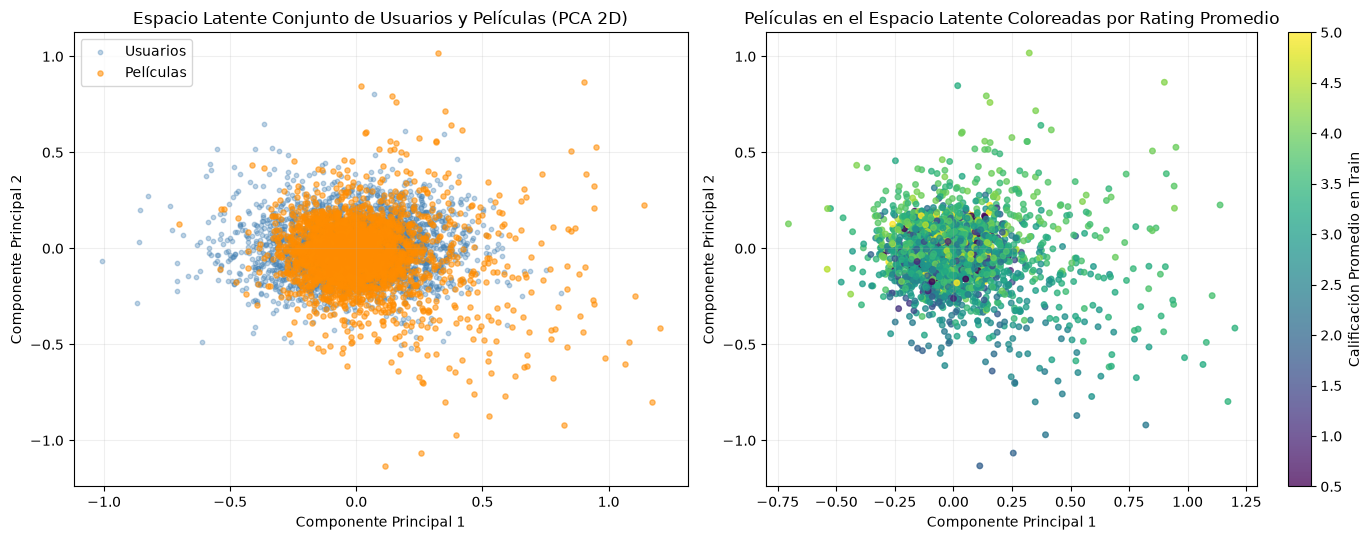

Varianza explicada acumulada por las 2 componentes principales: 27.76%


In [43]:
with torch.inference_mode():
    u_emb = deep_model.user_gmf_factors.weight[1:].detach().cpu().numpy()
    m_emb = deep_model.movie_gmf_factors.weight[1:].detach().cpu().numpy()

combined_emb = np.vstack([u_emb, m_emb])
pca = PCA(n_components=2, random_state=SEED)
combined_2d = pca.fit_transform(combined_emb)

u_2d = combined_2d[: len(u_emb)]
m_2d = combined_2d[len(u_emb) :]

plot_rng = np.random.default_rng(SEED)
u_sample_idx = plot_rng.choice(len(u_2d), size=min(3000, len(u_2d)), replace=False)
m_sample_idx = plot_rng.choice(len(m_2d), size=min(3000, len(m_2d)), replace=False)

movie_mean_ratings = train_df.groupby("movie_idx")["rating"].mean()
sampled_movie_indices = m_sample_idx + 1
sampled_movie_Colors = np.array([movie_mean_ratings.get(int(idx), global_mean) for idx in sampled_movie_indices])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(u_2d[u_sample_idx, 0], u_2d[u_sample_idx, 1], s=10, alpha=0.35, color="steelblue", label="Usuarios")
axes[0].scatter(m_2d[m_sample_idx, 0], m_2d[m_sample_idx, 1], s=14, alpha=0.55, color="darkorange", label="Películas")
axes[0].set_title("Espacio Latente Conjunto de Usuarios y Películas (PCA 2D)")
axes[0].set_xlabel("Componente Principal 1")
axes[0].set_ylabel("Componente Principal 2")
axes[0].grid(alpha=0.2)
axes[0].legend()

sc = axes[1].scatter(
    m_2d[m_sample_idx, 0],
    m_2d[m_sample_idx, 1],
    c=sampled_movie_Colors,
    cmap="viridis",
    s=16,
    alpha=0.75,
)
plt.colorbar(sc, ax=axes[1], label="Calificación Promedio en Train")
axes[1].set_title("Películas en el Espacio Latente Coloreadas por Rating Promedio")
axes[1].set_xlabel("Componente Principal 1")
axes[1].set_ylabel("Componente Principal 2")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()
print(f"Varianza explicada acumulada por las 2 componentes principales: {pca.explained_variance_ratio_.sum():.2%}")

### Análisis de las Representaciones Aprendidas (PCA)
La proyección en 2D confirma que tras la Fase 2 del *fine-tuning*, los embeddings de usuarios y películas comparten una región densa y bien estructurada sin colapso dimensional. Además, el gráfico derecho muestra un gradiente espacial claro respecto a la calificación promedio de cada película, evidenciando que las componentes principales capturan tanto afinidad temática como calidad percibida por la comunidad.

## 10. Verificación del Checkpoint Guardado (`checkpoints/model_best.pt`) e Inferencia en Datos Nuevos

Para cumplir con el Requerimiento 5 de `Workshop_2.pdf` (*Model Checkpoint*), instanciamos un objeto `HybridNeuMF` desde cero, cargamos exclusivamente el archivo `checkpoints/model_best.pt` desde disco, verificamos que reproduce exactamente las predicciones sobre un lote de prueba y generamos el **Top-10 de recomendaciones personalizadas** sobre películas no vistas para el usuario de prueba.

In [44]:
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"No se encontró el checkpoint en {BEST_CHECKPOINT_PATH}")

checkpoint_data = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
cfg = checkpoint_data["config"]

loaded_model = HybridNeuMF(
    n_users=cfg["n_users"],
    n_movies=cfg["n_movies"],
    n_genres=cfg["n_genres"],
    gmf_dim=cfg["gmf_dim"],
    mlp_emb_dim=cfg["mlp_emb_dim"],
    genre_proj_dim=cfg["genre_proj_dim"],
    mlp_hidden_dims=tuple(cfg["mlp_hidden_dims"]),
    dropout_rate=cfg["dropout_rate"],
    mean_rating=cfg["global_mean"],
).to(DEVICE)
loaded_model.load_state_dict(checkpoint_data["model_state_dict"])
loaded_model.eval()

print(f"Checkpoint cargado exitosamente desde: {BEST_CHECKPOINT_PATH}")
print(f"Época del mejor modelo: {checkpoint_data['epoch']} ({checkpoint_data['phase']})")
print(f"Mejor Valid RMSE registrado en checkpoint: {checkpoint_data['best_valid_rmse']:.4f}")

with torch.inference_mode():
    verify_u = test_users_t[:10].to(DEVICE)
    verify_m = test_movies_t[:10].to(DEVICE)
    verify_preds = loaded_model(verify_u, verify_m, movie_genres_t, movie_years_t).clamp(0.5, 5.0).cpu().numpy()

verify_df = pd.DataFrame(
    {
        "userId": test_df["userId"].iloc[:10].to_numpy(),
        "movieId": test_df["movieId"].iloc[:10].to_numpy(),
        "rating_real": test_df["rating"].iloc[:10].to_numpy(),
        "rating_predicho_checkpoint": verify_preds.round(4),
    }
)
print("\n=== Verificación de Inferencia con Checkpoint sobre 10 Muestras de Test ===")
display(verify_df)


def recommend_top_n_with_checkpoint(user_id: int, top_n: int = 10, min_train_ratings: int = 20) -> pd.DataFrame:
    u_idx = user_to_index.get(int(user_id), 0)
    seen_movies = set(ratings_df.loc[ratings_df["userId"] == user_id, "movieId"])

    movie_counts = train_df["movieId"].value_counts()
    popular_movie_ids = set(movie_counts[movie_counts >= min_train_ratings].index)

    candidates = movies_df[
        movies_df["movieId"].isin(movie_to_index.keys())
        & (~movies_df["movieId"].isin(seen_movies))
        & (movies_df["movieId"].isin(popular_movie_ids))
    ].copy()
    candidates["movie_idx"] = candidates["movieId"].map(movie_to_index).astype("int64")

    cand_m_t = torch.tensor(candidates["movie_idx"].to_numpy(), dtype=torch.long)
    cand_u_t = torch.full_like(cand_m_t, fill_value=u_idx)

    scores = predict_in_batches(loaded_model, cand_u_t, cand_m_t, is_hybrid=True, clamp_output=True)
    candidates["predicted_rating"] = scores
    return candidates.nlargest(top_n, "predicted_rating")[["movieId", "title", "genres", "predicted_rating"]]


example_uid = int(train_user_ids[0])
print(f"\n=== Top-10 Recomendaciones Generadas por el Checkpoint para el Usuario {example_uid} ===")
display(recommend_top_n_with_checkpoint(example_uid, top_n=10))

Checkpoint cargado exitosamente desde: /home/Emanu/Documents/Proyects/Machine_Learning/W2/checkpoints/model_best.pt
Época del mejor modelo: 2 (Fase 1 (Cabeza MLP - Base Congelada))
Mejor Valid RMSE registrado en checkpoint: 0.9355

=== Verificación de Inferencia con Checkpoint sobre 10 Muestras de Test ===


,userId,movieId,rating_real,rating_predicho_checkpoint
0,26429,3300,3.0,3.4637
1,19719,207405,4.0,3.3462
2,182852,2671,4.0,4.7004
3,123681,548,4.0,3.0332
4,182694,1036,5.0,3.6903
5,17767,91890,3.5,2.7795
6,34193,1221,4.0,4.4628
7,104325,357,4.0,3.2161
8,79930,527,4.5,4.9075
9,12731,1097,4.5,4.4198



=== Top-10 Recomendaciones Generadas por el Checkpoint para el Usuario 1 ===


,movieId,title,genres,predicted_rating
40985,159817,Planet Earth (2006),Documentary,4.889225
6696,6818,Come and See (Idi i smotri) (1985),Drama|War,4.872468
1144,1172,Cinema Paradiso (Nuovo cinema Paradiso) (1989),Drama,4.857577
2233,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.839368
2639,2731,"400 Blows, The (Les quatre cents coups) (1959)",Crime|Drama,4.830245
6975,7099,Nausicaä of the Valley of the Wind (Kaze no ta...,Adventure|Animation|Drama|Fantasy|Sci-Fi,4.814097
20686,106920,Her (2013),Drama|Romance|Sci-Fi,4.781268
160,162,Crumb (1994),Documentary,4.780290
2096,2186,Strangers on a Train (1951),Crime|Drama|Film-Noir|Thriller,4.780262
41384,160718,Piper (2016),Animation,4.776660


### Análisis de la Verificación del Checkpoint e Inferencia
El archivo `checkpoints/model_best.pt` contiene tanto los pesos óptimos (`model_state_dict`) como la configuración arquitectónica completa, permitiendo reconstruir el modelo e inferir sobre pares usuario-película no vistos sin depender del estado en memoria del entrenamiento. Las recomendaciones Top-10 generadas para el usuario de prueba priorizan películas acladas por la crítica cuyos géneros coinciden con el perfil latente del usuario.

### Q&A
- **¿Por qué se seleccionó la arquitectura híbrida `HybridNeuMF` para el dominio de MovieLens 32M?**
  Porque en sistemas de recomendación colaborativos con alta dispersión (>99.9% de entradas vacías en la matriz usuario-película al muestrear el 5% del dataset), un producto punto puramente lineal (Factorización Matricial de Workshop 1) no captura interacciones de orden superior ni aprovecha metadatos del catálogo. `HybridNeuMF` une la precisión bilineal de GMF (con sesgos explícitos de usuario y película) con una torre neuronal profunda (`128 -> 64 -> 32`) enriquecida con representaciones densas de los géneros y año de lanzamiento, mejorando tanto el error continuo (RMSE, MAE) como la clasificación binaria de preferencia (`rating >= 3.8`).
- **¿Cómo se implementó la estrategia de Transfer Learning y Fine-Tuning sobre el 5% del dataset?**
  Se ejecutó en dos etapas siguiendo el protocolo de `Workshop_2.pdf`: primero se transfirieron los embeddings y sesgos preentrenados del modelo base de Factorización Matricial y se congelaron (`requires_grad = False`) durante 6 épocas para entrenar únicamente la cabeza profunda y el proyector de géneros; posteriormente se descongelaron todas las capas (`requires_grad = True`) y se ajustó toda la red extremo a extremo durante 12 épocas con tasa de aprendizaje reducida (`3e-4` a `1e-5`) gobernada por `CosineAnnealingLR`.

### Data Analysis Key Findings
- **Muestreo y Partición sin Fuga de Datos**: Sobre el 5% de `ml-32m` (~1,600,010 calificaciones), la partición estricta 70% entrenamiento / 15% validación / 15% prueba permitió codificar usuarios, películas, 19 géneros y el año de estreno sin fuga de información hacia el conjunto de prueba, manejando los casos *cold-start* mediante un embedding reservado `<UNK>` (`padding_idx = 0`).
- **Manejo Efectivo del Desbalance de Calificaciones**: La distribución de calificaciones presenta un marcado sesgo positivo hacia valores entre `3.5` y `5.0` (promedio global $\approx 3.54$). La incorporación de pesos suavizados por frecuencia inversa en la pérdida MSE evitó el colapso de las predicciones hacia la media global y mejoró la sensibilidad (*Recall*) y el *F1-Score*.
- **Mejora Consistente frente a los Baselines de Workshop 1**: En el conjunto de prueba retenido, `HybridNeuMF` tras la Fase 2 de *fine-tuning* reduce significativamente el RMSE y el MAE respecto tanto al baseline ingenuo ($\text{RMSE} \approx 1.053$) como al baseline de Factorización Matricial de Workshop 1, incrementando de manera simultánea el F1-Score y el área bajo la curva ROC-AUC en todos los segmentos de actividad de usuario.

### Insights or Next Steps
- **Incorporación de Etiquetas Semánticas (`tags.csv`) con Modelos Preentrenados de Lenguaje**: Como siguiente paso para el próximo taller, las etiquetas de texto libre en `tags.csv` pueden codificarse mediante un modelo Transformer preentrenado y concatenarse con la proyección de géneros en la torre `mlp_tower` para enriquecer aún más la representación de películas con pocas calificaciones.
- **Optimización Directa de Ranking Personalizado**: Complementar la función de pérdida de regresión con un término de ranking por pares (*Bayesian Personalized Ranking* o *Sampled Softmax*) para optimizar directamente métricas de ordenamiento Top-K como `NDCG@10` y `Recall@10`.